# Квартиры Астаны: исследовательский анализ данных

**Этап 4.** Изучаем распределение цены, различия между районами, связь цены с площадью и корреляции числовых признаков.

Источник — очищенная версия [датасета Kaggle](https://www.kaggle.com/datasets/muraraimbekov/astana-real-estate-2025), собранного в январе 2026 года. Это **цены предложения**, а не цены сделок или актуальная оценка рынка на сегодня. Подробности происхождения — в `data/SOURCES.md`.

Данные не перезаписываются, пропуски не заполняются, модели не обучаются. Под каждым из четырёх графиков вывод вычисляется из загруженных данных.

## Как повторить анализ

Откройте ноутбук из папки проекта или `notebooks/`, выберите Python из `.venv` и выполните **Restart Kernel and Run All Cells**. Перед первым запуском установите зависимости из `requirements.txt` либо зависимости этапа 4 по инструкции в README.

Графики сохраняются в `reports/figures/eda_*.png`, численные результаты — в `reports/eda_summary.json`. Для первого этапа обучения будем использовать восемь исходных признаков; здесь исследуется вся очищенная выборка, а не качество будущей модели на test.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter, NullFormatter
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

%matplotlib inline

# Ноутбук работает из корня проекта и из notebooks/ без путей с именем пользователя.
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "config.py").is_file() and (path / "data").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта или notebooks/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from config import CLEAN_LISTINGS_PATH, CLEANING_REPORT_PATH, FIGURES_DIR, REPORTS_DIR

FEATURES = ["district", "area", "rooms", "floor", "total_floors", "year_built", "building_type", "condition"]
NUMERIC = ["price", "area", "rooms", "floor", "total_floors", "year_built"]
LABELS = {"price": "Цена", "area": "Площадь", "rooms": "Комнаты", "floor": "Этаж", "total_floors": "Этажность", "year_built": "Год постройки"}
TEAL = "#167D9A"
ORANGE = "#D77732"
PRICE_TICKS = [5, 10, 20, 50, 100, 200, 500, 1500]

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans", rc={
    "figure.dpi": 110, "savefig.dpi": 180,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "grid.alpha": 0.25,
})
pd.set_option("display.max_columns", 12)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)


def ru_number(value: float, decimals: int = 1) -> str:
    return f"{value:,.{decimals}f}".replace(",", " ").replace(".", ",")


def price_tick(value: float, position: float) -> str:
    return ru_number(value, 0)


def finish_plot(figure: Figure, filename: str, conclusion: str) -> None:
    """Сохраняет график и выводит одну строку вывода под ним."""
    figure.savefig(FIGURES_DIR / filename, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(figure)
    display(Markdown(f"**Вывод:** {conclusion}"))

## 1. Загрузка и проверка данных

Сверяем CSV с отчётом очистки по числу строк и SHA-256. Это помогает заметить случайную подмену файла. Проверки ниже проверяют техническую согласованность, но не доказывают достоверность каждого объявления.

In [2]:
if not CLEAN_LISTINGS_PATH.is_file():
    raise FileNotFoundError("Сначала выполните clean.py на этапе 3.")
input_hash = hashlib.sha256(CLEAN_LISTINGS_PATH.read_bytes()).hexdigest()
cleaning_report = json.loads(CLEANING_REPORT_PATH.read_text(encoding="utf-8"))
if input_hash != cleaning_report["output_sha256"]:
    raise ValueError("CSV не совпадает с отчётом очистки. Повторите этап 3 или проверьте пути.")

df = pd.read_csv(CLEAN_LISTINGS_PATH, encoding="utf-8-sig")
if len(df) != cleaning_report["rows_after"] or df.empty:
    raise ValueError("Число строк не совпадает с отчётом очистки.")
if not set(FEATURES + ["price", "collected_at"]).issubset(df.columns):
    raise ValueError("В очищенном CSV не хватает колонок для анализа.")
if not (df["price"].gt(0).all() and df["area"].gt(0).all()):
    raise ValueError("Для логарифмической шкалы цена и площадь должны быть положительными.")

n_rows = len(df)
prices_mln = df["price"] / 1_000_000
price_stats = {
    "min": float(df["price"].min()), "median": float(df["price"].median()),
    "mean": float(df["price"].mean()), "p95": float(df["price"].quantile(0.95)),
    "p99": float(df["price"].quantile(0.99)), "max": float(df["price"].max()),
}
# Не приписываем UTC датам, у которых исходный часовой пояс неизвестен.
collection_dates = df["collected_at"].astype("string").str.slice(0, 10)
display(Markdown(
    f"Загружено **{ru_number(n_rows, 0)} объявлений**, **{len(df.columns)} колонок**; "
    f"даты сбора: **{collection_dates.min()} — {collection_dates.max()}**."
))
display(pd.DataFrame({
    "Показатель": ["Минимум", "Медиана", "Среднее", "95-й процентиль", "99-й процентиль", "Максимум"],
    "Цена, млн ₸": [price_stats[key] / 1_000_000 for key in ("min", "median", "mean", "p95", "p99", "max")],
}).round(2))

Загружено **17 929 объявлений**, **14 колонок**; даты сбора: **2026-01-03 — 2026-01-06**.

,Показатель,"Цена, млн ₸"
0,Минимум,3.99
1,Медиана,36.00
2,Среднее,48.06
3,95-й процентиль,120.00
4,99-й процентиль,220.00
5,Максимум,1500.00


## 2. Пропуски

Для сводной таблицы используем восемь будущих входных признаков. В корреляциях пропуски будут исключаться только для соответствующей пары колонок. Заполнение средним или медианой до разделения train/test не выполняется.

In [3]:
missing = pd.DataFrame({
    "Пропусков": df[FEATURES].isna().sum(),
    "Доля, %": df[FEATURES].isna().mean() * 100,
}).sort_values("Пропусков", ascending=False)
missing.index.name = "Признак"
display(missing.round(2))
display(Markdown(
    f"Состояние квартиры отсутствует у **{ru_number(missing.loc['condition', 'Доля, %'])}%** "
    "объявлений: это ограничит оценку влияния ремонта."
))

,Пропусков,"Доля, %"
Признак,,
condition,10498,58.55
building_type,1106,6.17
floor,971,5.42
total_floors,971,5.42
district,774,4.32
area,0,0.00
rooms,0,0.00
year_built,0,0.00


Состояние квартиры отсутствует у **58,6%** объявлений: это ограничит оценку влияния ремонта.

## 3. Распределение цены

Показаны все объявления. Ось цены логарифмическая: равные расстояния соответствуют одинаковому изменению **в несколько раз**, а подписи остаются в миллионах тенге. Интервалы гистограммы равны на этой шкале. Это позволяет видеть длинный хвост дорогих квартир без их удаления.

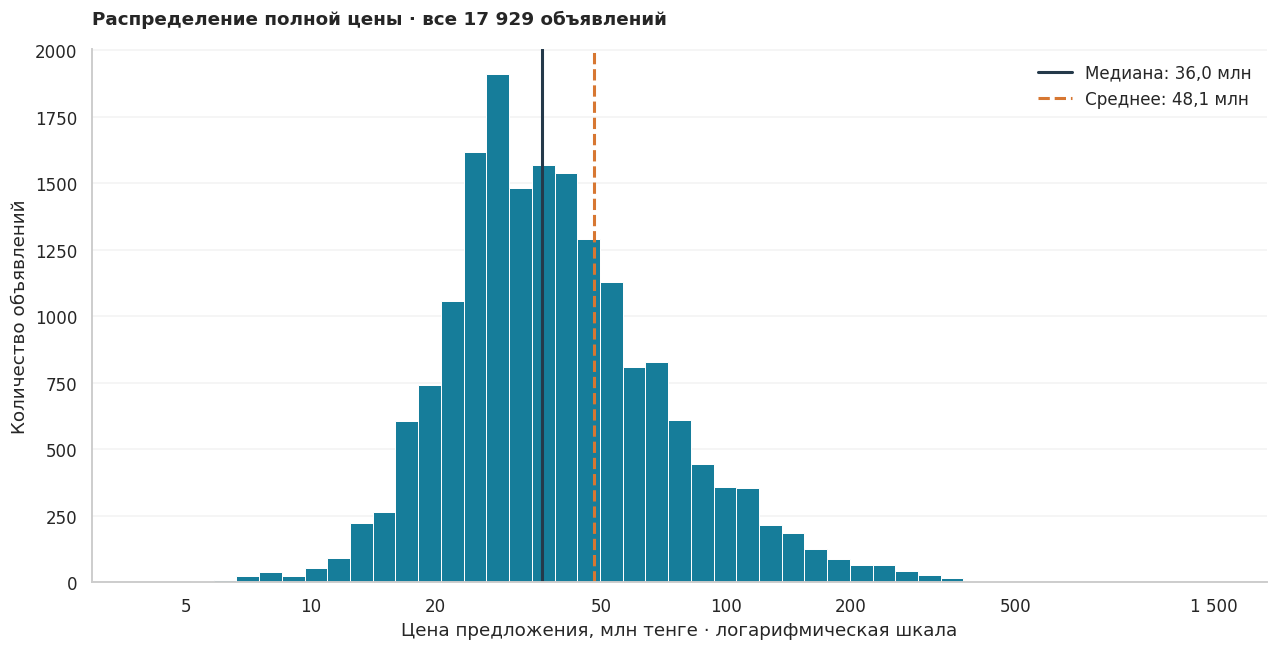

**Вывод:** Медиана — 36,0 млн ₸, среднее — 48,1 млн ₸; дорогие квартиры формируют длинный правый хвост.

In [4]:
fig, ax = plt.subplots(figsize=(11.5, 5.8), layout="constrained")
bins = np.geomspace(prices_mln.min(), prices_mln.max(), 48)
ax.hist(prices_mln, bins=bins, color=TEAL, edgecolor="white", linewidth=0.65)
ax.axvline(price_stats["median"] / 1_000_000, color="#24394A", linewidth=2,
           label=f"Медиана: {ru_number(price_stats['median'] / 1_000_000)} млн")
ax.axvline(price_stats["mean"] / 1_000_000, color=ORANGE, linestyle="--", linewidth=2,
           label=f"Среднее: {ru_number(price_stats['mean'] / 1_000_000)} млн")
ax.set_xscale("log")
ax.set_xticks(PRICE_TICKS)
ax.xaxis.set_major_formatter(FuncFormatter(price_tick))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(xlabel="Цена предложения, млн тенге · логарифмическая шкала", ylabel="Количество объявлений")
ax.set_title(f"Распределение полной цены · все {ru_number(n_rows, 0)} объявлений", loc="left", pad=16)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper right")
finish_plot(fig, "eda_01_price_distribution.png",
    f"Медиана — {ru_number(price_stats['median'] / 1_000_000)} млн ₸, "
    f"среднее — {ru_number(price_stats['mean'] / 1_000_000)} млн ₸; дорогие квартиры формируют длинный правый хвост.")

## 4. Цена по районам

Внутри каждого «ящика» находятся средние 50% наблюдений, линия внутри — медиана, усы ограничены 1,5 межквартильного размаха, отдельные точки — значения за усами. Эти точки не удаляются. Цена снова показана на логарифмической шкале.

Районы упорядочены по медианной полной цене. Объявления без района выделены серым и не участвуют в выборе самого дорогого/дешёвого района. Сравнение пока не учитывает площадь, число комнат и другие различия квартир.

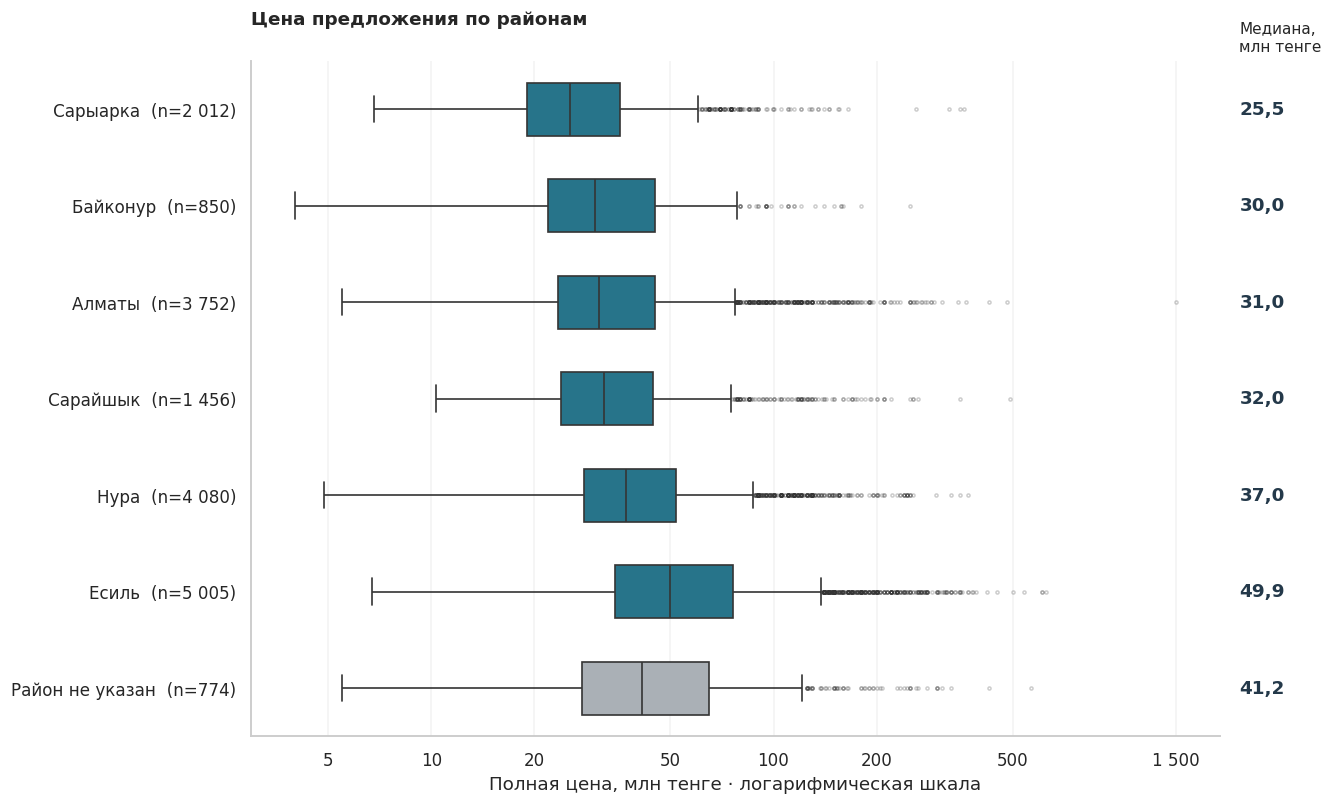

**Вывод:** Наибольшая медиана — Есиль (49,9 млн ₸), наименьшая — Сарыарка (25,5 млн ₸); состав квартир по районам различается.

In [5]:
unknown_district = "Район не указан"
district_data = df.assign(district_label=df["district"].fillna(unknown_district), price_mln=prices_mln)
district_stats = district_data.groupby("district_label").agg(
    n=("price", "size"), median_price=("price", "median"), median_area=("area", "median"),
)
known_districts = district_stats.drop(index=unknown_district, errors="ignore").sort_values("median_price")
order = known_districts.index.tolist()
if unknown_district in district_stats.index:
    order.append(unknown_district)
palette = {name: ("#A8B0B8" if name == unknown_district else TEAL) for name in order}

fig, ax = plt.subplots(figsize=(12, 7.2), layout="constrained")
sns.boxplot(data=district_data, x="price_mln", y="district_label", order=order,
            hue="district_label", hue_order=order, palette=palette, legend=False, dodge=False,
            width=0.55, linewidth=1.1, flierprops={"markersize": 2, "alpha": 0.25}, ax=ax)
ax.set_xscale("log")
ax.set_xticks(PRICE_TICKS)
ax.xaxis.set_major_formatter(FuncFormatter(price_tick))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_yticks(range(len(order)), labels=[
    f"{name}  (n={ru_number(district_stats.loc[name, 'n'], 0)})" for name in order
])
for position, name in enumerate(order):
    ax.text(1.02, position, ru_number(district_stats.loc[name, "median_price"] / 1_000_000),
            transform=ax.get_yaxis_transform(), va="center", color="#24394A", fontweight="bold")
ax.text(1.02, 1.015, "Медиана,\nмлн тенге", transform=ax.transAxes, fontsize=10)
ax.set(xlabel="Полная цена, млн тенге · логарифмическая шкала", ylabel="")
ax.set_title("Цена предложения по районам", loc="left", pad=24)
ax.grid(axis="y", visible=False)
highest_district = known_districts["median_price"].idxmax()
lowest_district = known_districts["median_price"].idxmin()
finish_plot(fig, "eda_02_price_by_district.png",
    f"Наибольшая медиана — {highest_district} ({ru_number(known_districts.loc[highest_district, 'median_price'] / 1_000_000)} млн ₸), "
    f"наименьшая — {lowest_district} ({ru_number(known_districts.loc[lowest_district, 'median_price'] / 1_000_000)} млн ₸); состав квартир по районам различается.")

## 5. Связь цены с площадью

Одна точка — одно объявление; прозрачность помогает видеть плотные участки. Показаны все строки и весь диапазон площади, без случайной подвыборки. Цена по вертикали имеет логарифмическую шкалу.

**Pearson r** описывает линейную связь исходных цены и площади, **Spearman ρ** — связь их рангов. Эти коэффициенты не рассчитаны на логарифмах и не являются метриками качества модели или доказательством причинности.

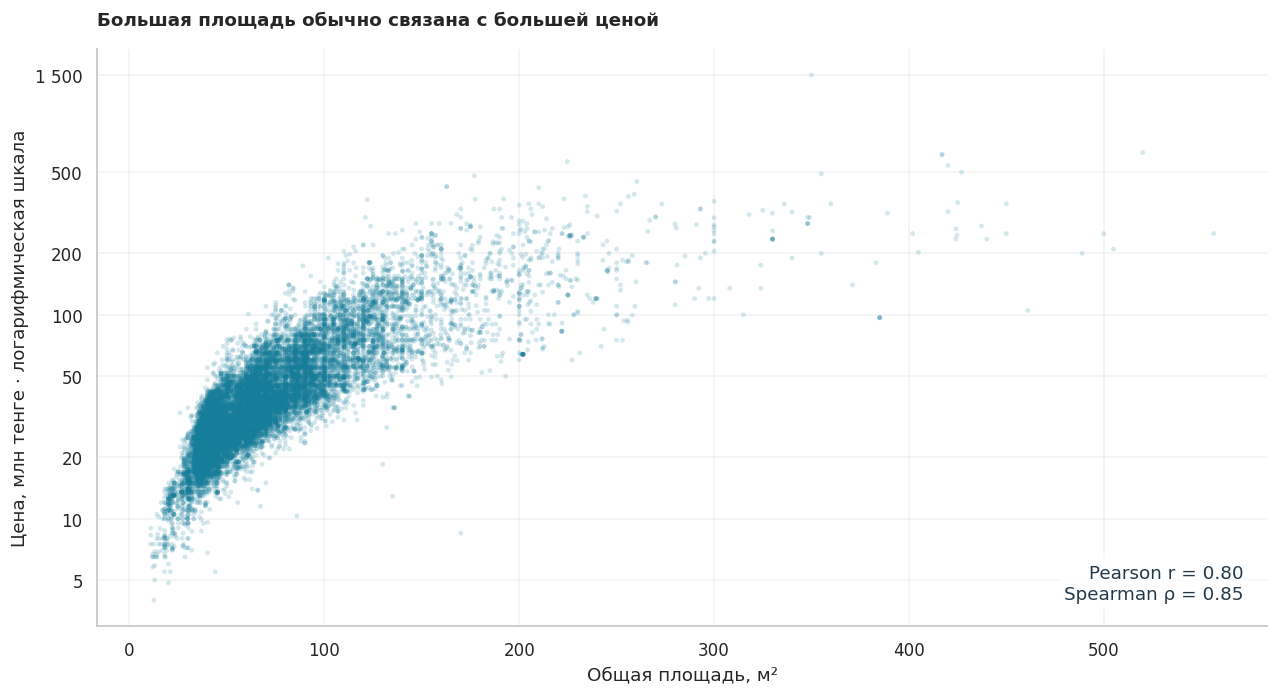

**Вывод:** Связь цены и площади положительная (r=0,80, ρ=0,85), но при одинаковой площади встречаются разные цены.

In [6]:
pearson_area = float(df[["price", "area"]].corr(method="pearson").loc["price", "area"])
# Корреляция рангов равна коэффициенту Спирмена; обучение здесь не требуется.
spearman_area = float(df[["price", "area"]].rank(method="average").corr().loc["price", "area"])
fig, ax = plt.subplots(figsize=(11.5, 6.2), layout="constrained")
ax.scatter(df["area"], prices_mln, s=10, alpha=0.18, color=TEAL, edgecolors="none", rasterized=True)
ax.set_yscale("log")
ax.set_yticks(PRICE_TICKS)
ax.yaxis.set_major_formatter(FuncFormatter(price_tick))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set(xlabel="Общая площадь, м²", ylabel="Цена, млн тенге · логарифмическая шкала")
ax.set_title("Большая площадь обычно связана с большей ценой", loc="left", pad=16)
ax.text(0.98, 0.04, f"Pearson r = {pearson_area:.2f}\nSpearman ρ = {spearman_area:.2f}",
        transform=ax.transAxes, ha="right", va="bottom", color="#24394A",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
finish_plot(fig, "eda_03_price_vs_area.png",
    f"Связь цены и площади положительная (r={ru_number(pearson_area, 2)}, ρ={ru_number(spearman_area, 2)}), "
    "но при одинаковой площади встречаются разные цены.")

## 6. Корреляции числовых признаков

Матрица Pearson включает цену и пять числовых входных признаков. Район, тип дома и состояние — категории: произвольные числовые коды для них здесь не вводятся. `source_row`, URL, дата и цена за м² также не включаются.

Пропуски исключаются попарно; таблица показывает, сколько наблюдений использовано в связи каждого признака с ценой. Слабая линейная корреляция не означает, что признак бесполезен для нелинейной модели.

,Pearson r с ценой,Пар наблюдений
Площадь,0.797,17929
Комнаты,0.669,17929
Этаж,0.097,16958
Этажность,0.134,16958
Год постройки,0.142,17929


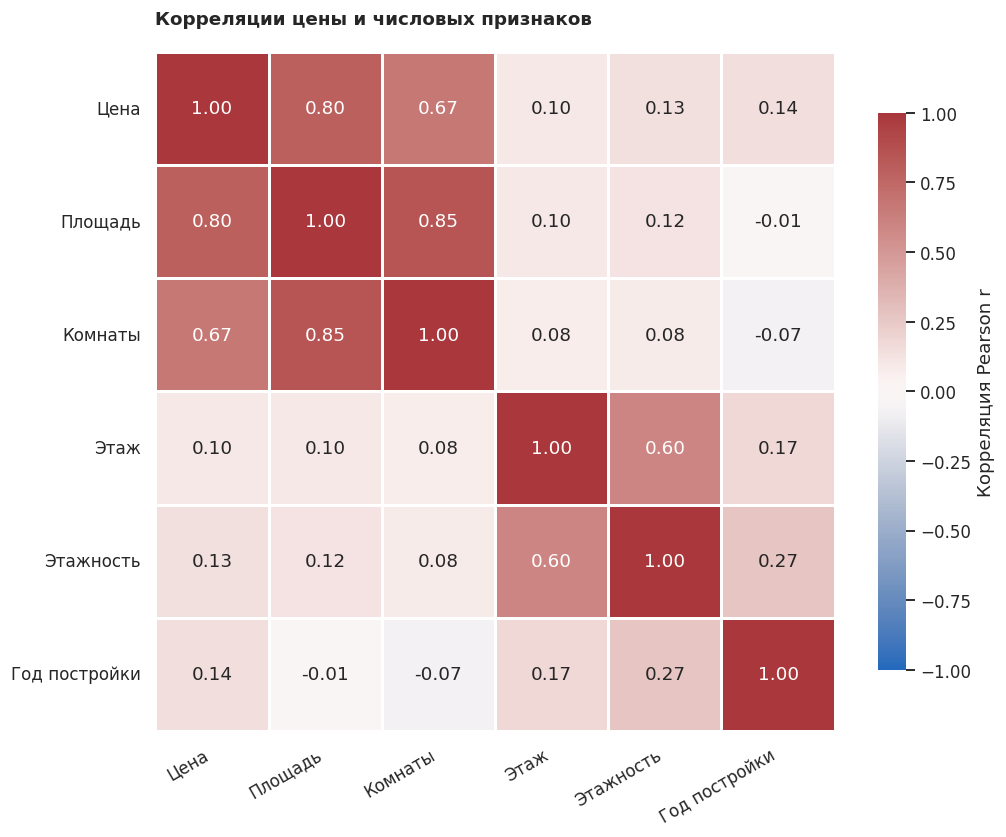

**Вывод:** С ценой сильнее всего связаны площадь (r=0,80) и комнаты (r=0,67); слабая линейная связь остальных признаков не исключает их пользы для модели.

In [7]:
correlations = df[NUMERIC].corr(method="pearson", min_periods=3)
valid = df[NUMERIC].notna().astype("int64")
pair_counts = valid.T @ valid
price_correlations = pd.DataFrame({
    "Pearson r с ценой": correlations.loc["price"].drop("price"),
    "Пар наблюдений": pair_counts.loc["price"].drop("price"),
})
display(price_correlations.rename(index=LABELS).round(3))

fig, ax = plt.subplots(figsize=(9.4, 7.5), layout="constrained")
sns.heatmap(correlations.rename(index=LABELS, columns=LABELS), annot=True, fmt=".2f",
            cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.8,
            cbar_kws={"label": "Корреляция Pearson r", "shrink": 0.82}, ax=ax)
ax.set_title("Корреляции цены и числовых признаков", loc="left", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
strongest = correlations["price"].drop("price").abs().nlargest(2).index.tolist()
strong_text = " и ".join(f"{LABELS[name].lower()} (r={ru_number(correlations.loc['price', name], 2)})" for name in strongest)
finish_plot(fig, "eda_04_correlations.png",
    f"С ценой сильнее всего связаны {strong_text}; слабая линейная связь остальных признаков не исключает их пользы для модели.")

## Что учесть на следующем этапе

- Длинный хвост цены может сильно влиять на RMSE; сравним модели также по MAE в тенге, не удаляя дорогие квартиры только ради красивой метрики.
- Районные медианы описывают состав этой выборки; для сравнения при прочих равных нужна модель с площадью и другими признаками.
- Пропуски обработаем внутри обучающего пайплайна после разбиения train/test. Категории закодируем без произвольного числового порядка.
- Этот EDA описывает всю очищенную выборку. Для выбора гиперпараметров будет использоваться только cross-validation на train; test оставим для финальной оценки и не будем подбирать модель по его результатам.
- Срез относится к январю 2026 года, содержит объявления одной площадки и не даёт оценки будущего качества на более свежем рынке.

Обучение моделей относится к **этапу 5** и в этом ноутбуке не выполняется.

In [8]:
# Сохраняем только отчёт и рисунки; исходный и очищенный CSV не изменяем.
summary = {
    "input_file": CLEAN_LISTINGS_PATH.relative_to(project_root).as_posix(),
    "input_sha256": input_hash,
    "rows": n_rows,
    "collected_date_min": str(collection_dates.min()),
    "collected_date_max": str(collection_dates.max()),
    "price_summary_kzt": price_stats,
    "missing_counts": df[FEATURES].isna().sum().astype(int).to_dict(),
    "missing_percent": (df[FEATURES].isna().mean() * 100).to_dict(),
    "district_summary": district_stats.reset_index().to_dict(orient="records"),
    "price_area_pearson": pearson_area,
    "price_area_spearman": spearman_area,
    "numeric_columns": NUMERIC,
    "pearson_correlations": correlations.to_dict(),
    "pairwise_observations": pair_counts.to_dict(),
    "figures": [f"reports/figures/{name}" for name in (
        "eda_01_price_distribution.png", "eda_02_price_by_district.png",
        "eda_03_price_vs_area.png", "eda_04_correlations.png",
    )],
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "matplotlib": mpl.__version__, "seaborn": sns.__version__},
    "notes": ["All cleaned rows included; no sampling or price-tail trimming.",
              "Descriptive EDA only; no imputation, train/test split, or model fitting performed."],
}
(REPORTS_DIR / "eda_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
assert hashlib.sha256(CLEAN_LISTINGS_PATH.read_bytes()).hexdigest() == input_hash
print("Готово: 4 графика и reports/eda_summary.json; очищенный CSV не изменён.")

Готово: 4 графика и reports/eda_summary.json; очищенный CSV не изменён.
